In [2]:
from qiskit import QuantumCircuit, QuantumRegister,ClassicalRegister,transpile
from qiskit.circuit.library import CDKMRippleCarryAdder
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit.circuit.library import MCXGate

In [39]:
N = 4  # number of bits

# registers
a = QuantumRegister(N, "a")
b = QuantumRegister(N, "b")
m = ClassicalRegister(N,"m")
carry = QuantumRegister(3, "carry")

qc = QuantumCircuit(a, b, carry,m)

# Example: a = 5 (00000101), b = 3 (00000011)
qc.x(a[0])
qc.x(a[2])

#encode 3 in b
qc.x(b[0])
qc.x(b[1])
#2s complement
qc.x(a)
qc.x(carry[0])
# CDKM adder
adder = CDKMRippleCarryAdder(N, kind="full")


qc.append(adder, [carry[0]]+ a[:] + b[:] + [carry[1]])

qc.x(a)
qc.x(carry[0])
qc.append(adder, [carry[0]]+ a[:] + b[:] + [carry[2]])
# qc.append(mcx, controls + [f[0]])


qc.measure(b,m)

adder.decompose().draw()

┌──────┐                                                     ┌──────┐
 cin: ┤2     ├─────────────────────────────────────────────────────┤2     ├
      │      │┌──────┐                                     ┌──────┐│      │
 a_0: ┤0     ├┤2     ├─────────────────────────────────────┤2     ├┤0     ├
      │      ││      │┌──────┐                     ┌──────┐│      ││      │
 a_1: ┤      ├┤0     ├┤2     ├─────────────────────┤2     ├┤0     ├┤      ├
      │  MAJ ││      ││      │┌──────┐     ┌──────┐│      ││      ││  UMA │
 a_2: ┤      ├┤      ├┤0     ├┤2     ├─────┤2     ├┤0     ├┤      ├┤      ├
      │      ││  MAJ ││      ││      │     │      ││      ││  UMA ││      │
 a_3: ┤      ├┤      ├┤      ├┤0     ├──■──┤0     ├┤      ├┤      ├┤      ├
      │      ││      ││  MAJ ││      │  │  │      ││  UMA ││      ││      │
 b_0: ┤1     ├┤      ├┤      ├┤      ├──┼──┤      ├┤      ├┤      ├┤1     ├
      └──────┘│      ││      ││  MAJ │  │  │  UMA ││      ││      │└──────┘
 b_1: ────────┤1     ├┤      ├┤      ├──┼──┤      ├┤      ├┤1     ├────────
              └──────┘│      ││      │  │  │      ││      │└──────┘        
 b_2: ────────────────┤1     ├┤      ├──┼──┤      ├┤1     ├────────────────
                      └──────┘│      │  │  │      │└──────┘                
 b_3: ────────────────────────┤1     ├──┼──┤1     ├────────────────────────
                              └──────┘┌─┴─┐└──────┘                        
cout: ────────────────────────────────┤ X ├────────────────────────────────
                                      └───┘

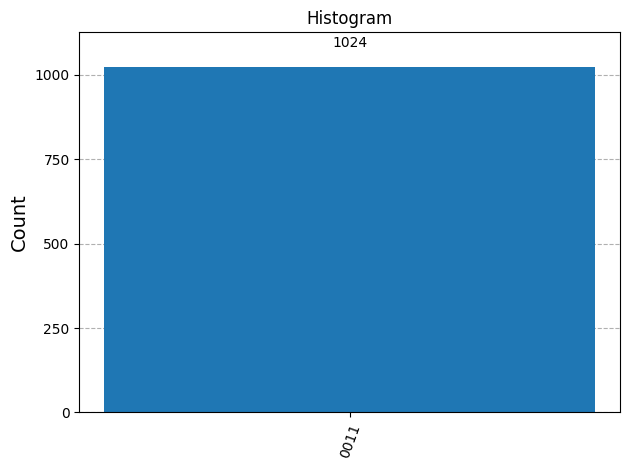

In [12]:
# Transpile for simulator
simulator = AerSimulator()
qc = transpile(qc, simulator)
results = simulator.run(qc).result()
counts = results.get_counts()
plot_histogram(counts, title="Histogram")



In [156]:
print(counts)

{'01': 1024}


In [ ]:
answer = results.get_counts()
#Get the result with the maximum number of counts
max_item =max(answer.items(), key=operator.itemgetter(1))
print(max_item[0])
solution_individual=string_to_list(max_item[0])
_,new_fitness_value=calculate_individual_fitness(solution_individual)
new_fitness_value = abs(new_fitness_value)
print("Found solution {0} with fitness {1}...".format(max_item[0],new_fitness_value))
final_results.append(generation, new_fitness_value)

# Grover

In [111]:
from qiskit import QuantumCircuit, QuantumRegister,ClassicalRegister,transpile
from qiskit.circuit.library import CDKMRippleCarryAdder
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit.circuit.library import MCXGate
from qiskit.circuit.library import GroverOperator

In [129]:
qc = QuantumCircuit(4,3)
qc.x(3)
qc.barrier()
qc.h([0,1,2,3])
qc.barrier()
# oracle
qc.mcx([0,1,2], 3)
qc.barrier()
#amplify
qc.h([0,1,2])
qc.x([0,1,2])
qc.h(2)
qc.ccx(0,1,2)
qc.h(2)
qc.x([0,1,2])
qc.h([0,1,2,3])

qc.measure([0,1,2],[0,1,2])
qc.draw()

░ ┌───┐ ░       ░ ┌───┐┌───┐          ┌───┐┌───┐     ┌─┐      
q_0: ──────░─┤ H ├─░───■───░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├─────┤M├──────
           ░ ├───┤ ░   │   ░ ├───┤├───┤       │  ├───┤├───┤     └╥┘┌─┐   
q_1: ──────░─┤ H ├─░───■───░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────╫─┤M├───
           ░ ├───┤ ░   │   ░ ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐ ║ └╥┘┌─┐
q_2: ──────░─┤ H ├─░───■───░─┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├─╫──╫─┤M├
     ┌───┐ ░ ├───┤ ░ ┌─┴─┐ ░ ├───┤└───┘└───┘└───┘└───┘└───┘└───┘ ║  ║ └╥┘
q_3: ┤ X ├─░─┤ H ├─░─┤ X ├─░─┤ H ├───────────────────────────────╫──╫──╫─
     └───┘ ░ └───┘ ░ └───┘ ░ └───┘                               ║  ║  ║ 
c: 3/════════════════════════════════════════════════════════════╩══╩══╩═
                                                                 0  1  2

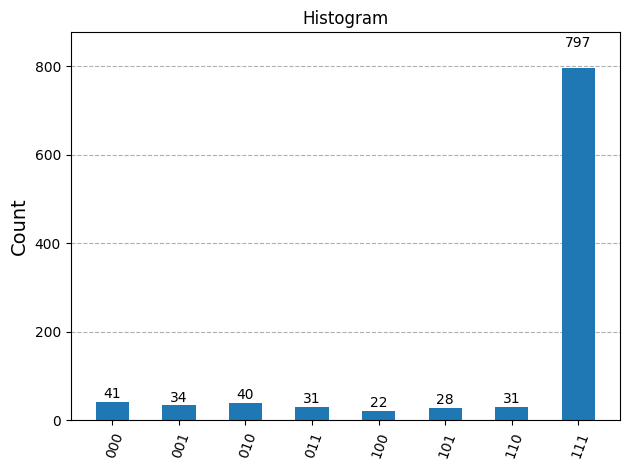

In [130]:
# Transpile for simulator
simulator = AerSimulator()
qc = transpile(qc, simulator)
results = simulator.run(qc).result()
counts = results.get_counts()
plot_histogram(counts, title="Histogram")



In [146]:
# 1) Build the oracle using the workspace qubit
oracle = QuantumCircuit(4)

# Your oracle marks |111> on first 3 qubits
# using qubit 3 as target for MCX
oracle.h(3)               # prepare target for phase flip
oracle.mcx([0,1,2], 3)    # flip target
oracle.h(3)               # uncompute target


grover_op = GroverOperator(oracle,insert_barriers =True)

# 3) Build the main circuit
qc = QuantumCircuit(4,3)  # measure only first 3 qubits
qc.h(range(4))            # uniform superposition
qc.barrier()

# 4) Apply Grover iterations (1 iteration here)
qc.append(grover_op, range(4))

# 5) Measure
qc.measure([0,1,2],[0,1,2])
grover_op.decompose().draw()

C:\Users\sardelean.SAGUARO\AppData\Local\Temp\ipykernel_35324\1442867888.py:11: DeprecationWarning: The class ``qiskit.circuit.library.grover_operator.GroverOperator`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use qiskit.circuit.library.grover_operator instead.
  grover_op = GroverOperator(oracle,insert_barriers =True)


global phase: π
                         ░ ┌───┐ ░ ┌───┐          ┌───┐      ░ ┌───┐
state_0: ───────■────────░─┤ H ├─░─┤ X ├───────■──┤ X ├──────░─┤ H ├
                │        ░ ├───┤ ░ ├───┤       │  ├───┤      ░ ├───┤
state_1: ───────■────────░─┤ H ├─░─┤ X ├───────■──┤ X ├──────░─┤ H ├
                │        ░ ├───┤ ░ ├───┤       │  ├───┤      ░ ├───┤
state_2: ───────■────────░─┤ H ├─░─┤ X ├───────■──┤ X ├──────░─┤ H ├
         ┌───┐┌─┴─┐┌───┐ ░ ├───┤ ░ ├───┤┌───┐┌─┴─┐├───┤┌───┐ ░ ├───┤
state_3: ┤ H ├┤ X ├┤ H ├─░─┤ H ├─░─┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├─░─┤ H ├
         └───┘└───┘└───┘ ░ └───┘ ░ └───┘└───┘└───┘└───┘└───┘ ░ └───┘

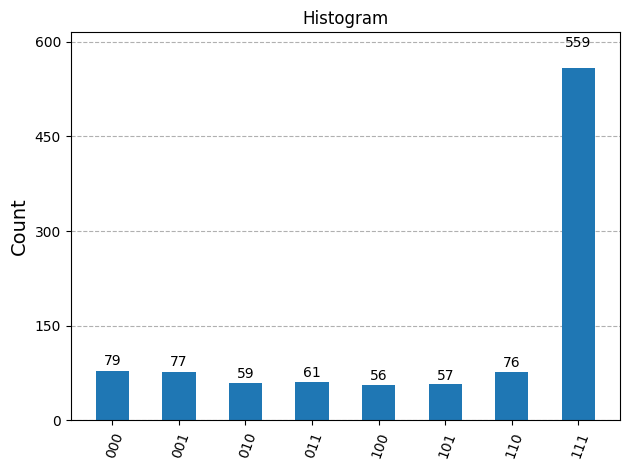

In [135]:
# Transpile for simulator
simulator = AerSimulator()
qc = transpile(qc, simulator)
results = simulator.run(qc).result()
counts = results.get_counts()
plot_histogram(counts, title="Histogram")



In [147]:
value = [0,1,2,3,4]
value[:]

[0, 1, 2, 3, 4]

In [153]:
value[]

[0, 1, 2, 3]

In [36]:
N = 4  # number of bits

# registers
a = QuantumRegister(N, "a")
b = QuantumRegister(N, "b")
m = ClassicalRegister(1,"m")

helps = QuantumRegister(1, "help")
qc = QuantumCircuit(a, b, helps,m)

# Example: a = 5 (00000101), b = 3 (00000011)
# qc.x(a[0])
# qc.x(a[2])
qc.x(a[:])

#encode 3 in b
qc.x(b[0])
#qc.x(b[1])
#2s complement

# CDKM adder
adder = CDKMRippleCarryAdder(N, kind="fixed")


qc.append(adder, a[:] + b[:] + [helps[0]])




qc.measure(helps,m)

adder.decompose().draw()

┌──────┐┌──────┐                                ┌──────┐┌──────┐
 a_0: ┤0     ├┤2     ├────────────────────────────────┤2     ├┤0     ├
      │      ││      │┌──────┐                ┌──────┐│      ││      │
 a_1: ┤      ├┤0     ├┤2     ├────────────────┤2     ├┤0     ├┤      ├
      │      ││      ││      │┌──────┐┌──────┐│      ││      ││      │
 a_2: ┤      ├┤      ├┤0     ├┤2     ├┤2     ├┤0     ├┤      ├┤      ├
      │      ││  MAJ ││      ││      ││      ││      ││  UMA ││      │
 a_3: ┤      ├┤      ├┤      ├┤0     ├┤0     ├┤      ├┤      ├┤      ├
      │      ││      ││  MAJ ││      ││      ││  UMA ││      ││      │
 b_0: ┤1 MAJ ├┤      ├┤      ├┤      ├┤      ├┤      ├┤      ├┤1 UMA ├
      │      ││      ││      ││  MAJ ││  UMA ││      ││      ││      │
 b_1: ┤      ├┤1     ├┤      ├┤      ├┤      ├┤      ├┤1     ├┤      ├
      │      │└──────┘│      ││      ││      ││      │└──────┘│      │
 b_2: ┤      ├────────┤1     ├┤      ├┤      ├┤1     ├────────┤      ├
      │      │        └──────┘│      ││      │└──────┘        │      │
 b_3: ┤      ├────────────────┤1     ├┤1     ├────────────────┤      ├
      │      │                └──────┘└──────┘                │      │
help: ┤2     ├────────────────────────────────────────────────┤2     ├
      └──────┘                                                └──────┘

In [37]:
qc.draw()

┌───┐┌───────────────────────┐   
 a_0: ┤ X ├┤0                      ├───
      ├───┤│                       │   
 a_1: ┤ X ├┤1                      ├───
      ├───┤│                       │   
 a_2: ┤ X ├┤2                      ├───
      ├───┤│                       │   
 a_3: ┤ X ├┤3                      ├───
      ├───┤│                       │   
 b_0: ┤ X ├┤4 CDKMRippleCarryAdder ├───
      └───┘│                       │   
 b_1: ─────┤5                      ├───
           │                       │   
 b_2: ─────┤6                      ├───
           │                       │   
 b_3: ─────┤7                      ├───
           │                       │┌─┐
help: ─────┤8                      ├┤M├
           └───────────────────────┘└╥┘
 m: 1/═══════════════════════════════╩═
                                     0

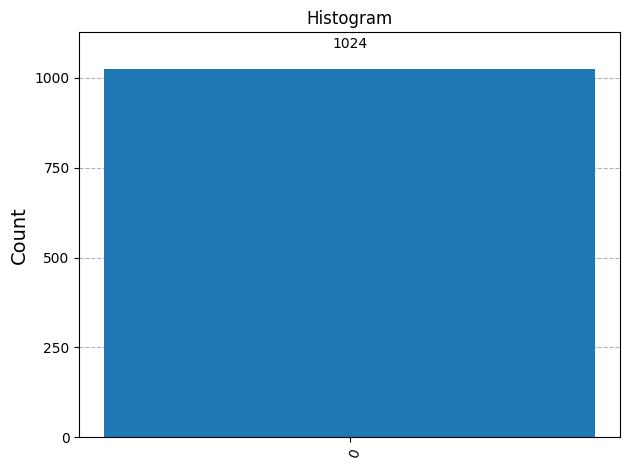

In [38]:
# Transpile for simulator
simulator = AerSimulator()
qc = transpile(qc, simulator)
results = simulator.run(qc).result()
counts = results.get_counts()
plot_histogram(counts, title="Histogram")